# Collision Test
This notebook is used to process the data from the collision test. 

In [21]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path("collision_test_data")   # next to this notebook
RUN = "collision_live_plot_20261020_153631"   # CSV of collision_live_plot.py, without .csv


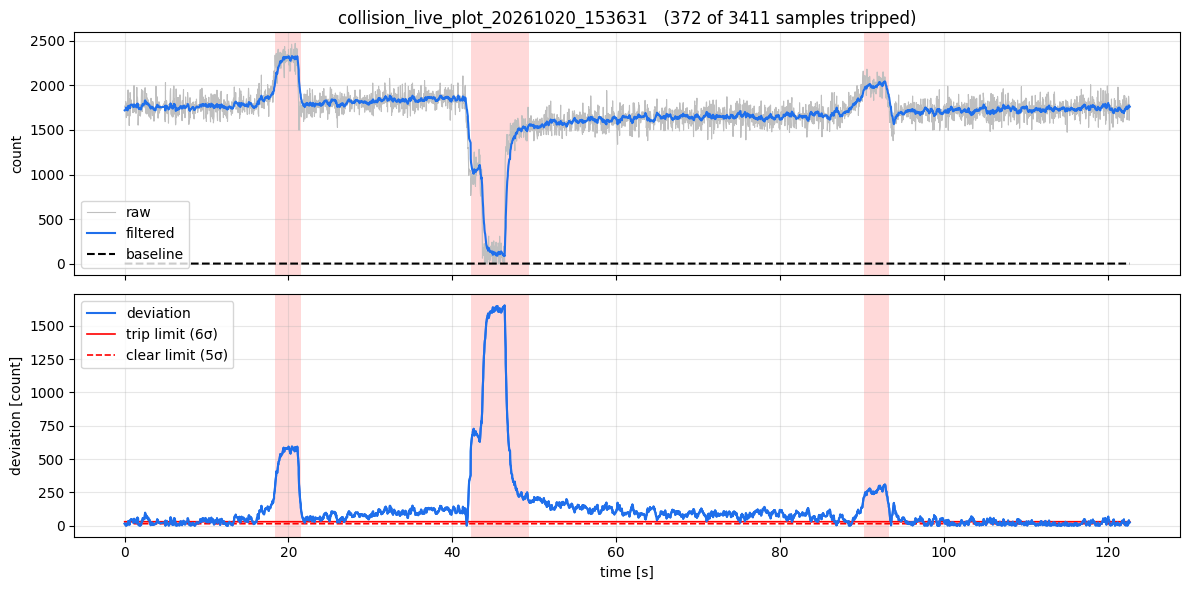

In [22]:
data = pd.read_csv(DATA_DIR / f"{RUN}.csv", usecols=["t_pc_s", "raw", "filtered", "baseline", "deviation","sigma", "trip"])
t = data.t_pc_s

fig, (ax_count, ax_dev) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax_count.plot(t, data.raw, color="0.75", lw=0.8, label="raw")
ax_count.plot(t, data.filtered, color="#1f6feb", lw=1.5, label="filtered")
ax_count.plot(t, data.baseline, color="black", lw=1.5, ls="--", label="baseline")
ax_count.set_ylabel("count")
ax_count.legend(loc="lower left")
ax_count.set_title(f"{RUN}   ({int(data.trip.sum())} of {len(data)} samples tripped)")

# trip / clear limits as in the firmware AUTO mode: K·sigma, with a floor
trip_limit = (6 * data.sigma).clip(lower=30)    # AUTO_K_TRIP, AUTO_DEV_FLOOR
clear_limit = (5 * data.sigma).clip(lower=15)   # AUTO_K_CLEAR, AUTO_DEV_FLOOR / 2

ax_dev.plot(t, data.deviation, color="#1f6feb", lw=1.5, label="deviation")
ax_dev.plot(t, trip_limit, color="red", lw=1.2, label="trip limit (6σ)")
ax_dev.plot(t, clear_limit, color="red", lw=1.2, ls="--", label="clear limit (5σ)")
ax_dev.legend(loc="upper left")


ax_dev.plot(t, data.deviation, color="#1f6feb", lw=1.5)
ax_dev.set_ylabel("deviation [count]")
ax_dev.set_xlabel("time [s]")

# tripped samples: red band on both panels
for ax in (ax_count, ax_dev):
    ax.fill_between(t, 0, 1, where=data.trip == 1, transform=ax.get_xaxis_transform(),
                    color="red", alpha=0.15, lw=0)
    ax.grid(alpha=0.3)
plt.tight_layout()
